# Автоматизация расчёта продуктовых метрик

## Цель работы

Реализовать функции для загрузки дополнительных данных A/B-эксперимента, их предобработки, повторного расчёта продуктовых метрик и визуализации результатов.

В работе используются три функции:

- `preprocess_data()` - приводит названия и типы столбцов к единому формату;
- `calculate_metrics()` - при вызове загружает дополнительный CSV, объединяет данные и рассчитывает CR, ARPU и ARPPU по экспериментальным группам;
- `plot_metrics()` - строит графики для сравнения метрик групп A и B.

Проект выполнен в рамках курса «Аналитик данных» от [Karpov.Courses](https://karpov.courses/).

Постановка задачи и исходные учебные данные предоставлены ООО «Карпов Курсы». Исходные данные курса не распространяются в репозитории.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Загрузка данных

Для расчёта используются четыре CSV-файла:

- `Проект_2_groups.csv` - распределение пользователей по группам A и B;
- `Проект_2_group_add.csv` - дополнительный список пользователей, полученный позднее;
- `Проект_2_active_studs.csv` - активные пользователи в период эксперимента;
- `Проект_2_checks.csv` - информация об оплатах.

Основные файлы загружаем с помощью `pandas`. Дополнительный файл `Проект_2_group_add.csv` будет прочитан внутри `calculate_metrics()` при вызове функции, ниже передадим в неё путь к файлу.

Исходные CSV не включены в публичную версию проекта.

In [2]:
groups = pd.read_csv('Проект_2_groups.csv')
active = pd.read_csv('Проект_2_active_studs.csv')
checks = pd.read_csv('Проект_2_checks.csv')

## Предобработка данных

В исходных файлах названия и форматы столбцов различаются. Функция `preprocess_data()` приводит их к единому виду, чтобы таблицы можно было объединить. Для дополнительного файла предусмотрены два варианта названия идентификатора пользователя: `id` и `student_id`.

In [3]:
# Сначала создадим функцию, которая будет предобрабатывать данные и приводить их к единому виду

def preprocess_data(groups, groups_add, checks):

    if 'id;grp' in groups.columns:
        groups[['student_id', 'grp']] = groups['id;grp'].str.split(';', expand=True)
        groups = groups.drop(columns='id;grp')
        groups['student_id'] = groups['student_id'].astype(int)

    if 'id' in groups_add.columns:
        groups_add = groups_add.rename(columns={'id': 'student_id'})

    if 'student_id;"rev"' in checks.columns:
        checks[['student_id', 'rev']] = checks['student_id;"rev"'].str.split(';', expand=True)
        checks = checks.drop(columns='student_id;"rev"')
        checks['student_id'] = checks['student_id'].astype(int)
        checks['rev'] = checks['rev'].astype(float)

    return groups, groups_add, checks

## Загрузка дополнительных данных и расчёт метрик

Функция `calculate_metrics()` при каждом вызове читает указанный дополнительный CSV через `pd.read_csv()`, затем вызывает функцию предобработки.

После этого она объединяет основной и дополнительный списки пользователей, оставляет активных участников эксперимента и присоединяет сведения об оплатах.

Для каждой группы рассчитываются:

- **CR** - доля активных пользователей, совершивших оплату;
- **ARPU** - средняя выручка на одного активного пользователя;
- **ARPPU** - средняя выручка на одного платящего пользователя.

Функция возвращает таблицу метрик и объединённый DataFrame, по которому выполнены расчёты.

In [4]:
# Функция для загрузки дополнительного файла и расчёта метрик

def calculate_metrics(groups, groups_add_path, active, checks):

    # При каждом вызове функции читаем актуальный дополнительный CSV
    groups_add = pd.read_csv(groups_add_path)

    # Приводим столбцы всех файлов к единому формату
    groups, groups_add, checks = preprocess_data(groups, groups_add, checks)

    # Объединяем группы
    groups_complete = pd.concat([groups, groups_add], ignore_index=True)

    # Оставляем только активных пользователей
    groups_active = groups_complete.merge(active, on='student_id')

    # Добавляем информацию о платежах
    df = groups_active.merge(checks, on='student_id', how='left')

    # Отмечаем платящих пользователей
    df['paid'] = df['rev'].notna()

    # Считаем метрики
    metrics = df.groupby('grp').agg(users=('student_id', 'count'), paying_users=('paid', 'sum'), revenue=('rev', 'sum'))

    # Конверсия
    metrics['CR'] = metrics['paying_users'] / metrics['users']

    # ARPU
    metrics['ARPU'] = metrics['revenue'] / metrics['users']

    # ARPPU
    metrics['ARPPU'] = metrics['revenue'] / metrics['paying_users']

    return metrics.reset_index(), df

## Визуализация метрик

Функция `plot_metrics()` строит три столбчатых графика для сравнения CR, ARPU и ARPPU между контрольной и экспериментальной группами.

На графике CR используется доля от 0 до 1, а не процентное значение.

In [5]:
# Функция для построения графиков по метрикам

def plot_metrics(metrics):

    # Конверсия
    plt.figure(figsize=(8, 6))
    sns.barplot(data=metrics, x='grp', y='CR')
    plt.title('Конверсия')
    plt.show()

    # ARPU
    plt.figure(figsize=(8, 6))
    sns.barplot(data=metrics, x='grp', y='ARPU')
    plt.title('ARPU')
    plt.show()

    # ARPPU
    plt.figure(figsize=(8, 6))
    sns.barplot(data=metrics, x='grp', y='ARPPU')
    plt.title('ARPPU')
    plt.show()

## Применение функций

Передаём функции `calculate_metrics()` путь к дополнительному файлу. Она сама загрузит его, подготовит данные и рассчитает метрики. Затем выведем результат и построим графики.

Если дополнительный CSV обновится, повторный вызов `calculate_metrics()` прочитает его заново и пересчитает показатели.

  grp  users  paying_users      revenue        CR       ARPU        ARPPU
0   A   1538            78   72820.0000  0.050715  47.347204   933.589744
1   B   6803           314  394974.0035  0.046156  58.058798  1257.878992


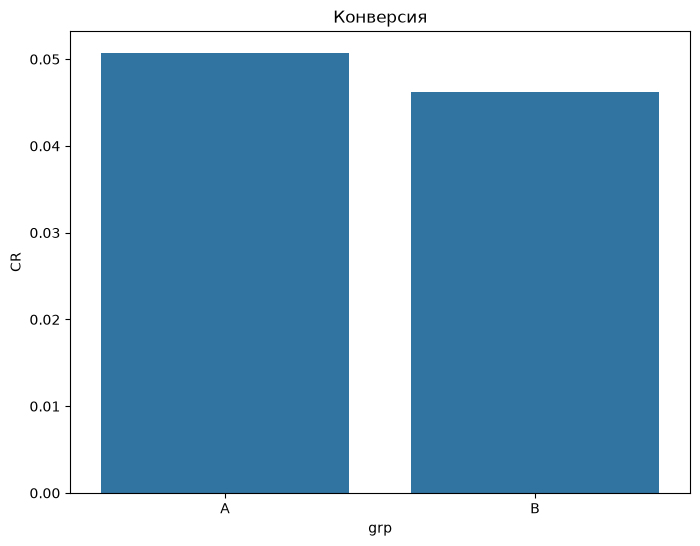

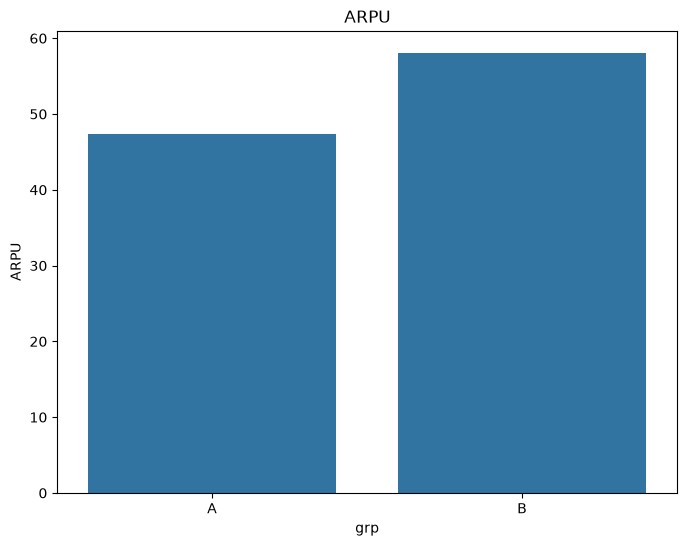

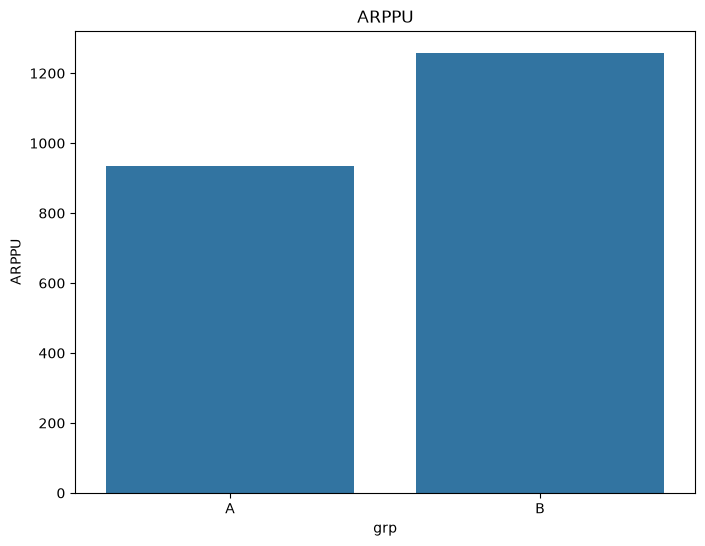

In [6]:
# Функция сама загружает дополнительный CSV и рассчитывает метрики
metrics, df = calculate_metrics(
    groups, 'Проект_2_group_add.csv', active, checks
)

# Выводим рассчитанные метрики
print(metrics)

# Строим графики
plot_metrics(metrics)

## Вывод

Реализованы функции для приведения входных данных к единому формату, повторного расчёта продуктовых метрик и построения графиков.

При вызове `calculate_metrics()` дополнительный CSV загружается из указанного файла, после чего рассчитываются CR, ARPU и ARPPU. При обновлении файла можно повторно вызвать функцию, не изменяя формулы расчёта.

Загрузка основного списка пользователей, данных активности и оплат выполняется отдельно перед вызовом функции.